# Phase 9 — Frozen test evaluation and interpretation (Runs A and B)

**Prerequisites:** `results/phase7_A.joblib` and `results/phase7_B.joblib` from the completed Phase 7 checkpoint cell. Neither Phase 8 nor this notebook reruns the expensive Phase 7 grid.

**Test-set rule:** Freeze the model specifications using training/validation **before** running the evaluation. For each run, an existing `results/run_A.csv` or `results/run_B.csv` is **read**, not recalculated. Do **not** adjust models after viewing test metrics. The optional outlier sensitivity must be selected **before the first evaluation** and is included in the same frozen assessment. Existing result CSV files take precedence over the optional setting.

Log-scale RMSE and R² compare predictions of log annual salary. Median dollar error is the median of `abs(exp(y_true) - exp(y_pred))`. `exp(RMSE)` is a rough multiplicative error scale, **not** a literal statement about the median or typical prediction.

**Report:** Run A measures performance on a future survey year (2026) after training through 2024 and validation on 2025. Run B measures held-out respondents from the same mixture of years. Differences also reflect training size and composition, not solely time shift.

**Cache provenance:** A preexisting results CSV is never automatically rescored. Confirm that it was produced by the current frozen Phase 7 checkpoint; the notebook cannot infer provenance solely from the filename.


In [10]:
# ============================================================
# PHASE 9a — LOAD FROZEN PHASE 7 RESULTS FOR RUNS A AND B
# ============================================================
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.linear_model import ElasticNet
from sklearn.metrics import r2_score, mean_squared_error, median_absolute_error
from sklearn.exceptions import ConvergenceWarning
import warnings
from IPython.display import display

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Choose BEFORE any test evaluation. Set True only if outlier sensitivity
# is part of the analysis you decided to report in advance.
RUN_OUTLIER_SENSITIVITY = False

phase9_data = {}

for RUN in ("A", "B"):
    path = RESULTS_DIR / f"phase7_{RUN}.joblib"
    if not path.is_file():
        raise FileNotFoundError(f"Missing Phase 7 checkpoint: {path}")

    # Load only trusted checkpoints: joblib files can execute Python code.
    d = joblib.load(path)
    assert d["RUN"] == RUN, f"Wrong run loaded from {path}"
    # Existing results may be read without re-scoring even for legacy checkpoints.
    # Fresh test scoring requires tuning_finalized=True.
    cached_result = RESULTS_DIR / f"run_{RUN}.csv"
    if not cached_result.exists() and d.get("tuning_finalized") is not True:
        raise ValueError(
            f"Run {RUN}: Phase 7 tuning must be marked finalized BEFORE first test scoring. "
            "Freeze the chosen settings in the checkpoint."
        )
    if cached_result.exists() and d.get("tuning_finalized") is not True:
        print(f"Run {RUN}: older/unfinished checkpoint metadata; loading cached results only. "
              "Verify those results match the frozen models.")

    required = ["Xt_tr", "Xt_te", "y_train", "y_test", "prep_all", "best", "ols", "baseline_value"]
    missing = [key for key in required if key not in d]
    if missing:
        raise KeyError(f"Run {RUN}: missing checkpoint keys {missing}")

    Xt_tr, Xt_te = d["Xt_tr"], d["Xt_te"]
    y_train, y_test = d["y_train"], d["y_test"]
    names = np.asarray(d["prep_all"].get_feature_names_out(), dtype=str)

    assert Xt_tr.shape[0] == len(y_train)
    assert Xt_te.shape[0] == len(y_test)
    assert Xt_tr.shape[1] == Xt_te.shape[1] == len(names)
    assert all(key in d["best"] for key in ("ridge", "lasso", "enet_naive", "enet_rescaled"))

    # A positive scalar correction preserves the naive model's zero pattern.
    selected = d["best"]["enet_rescaled"]
    model, extra = selected[1], selected[2]
    coef, b0 = extra
    factor = 1 + model.alpha * (1 - model.l1_ratio)
    np.testing.assert_allclose(np.asarray(coef), factor * np.asarray(model.coef_))
    assert len(coef) == len(names)

    phase9_data[RUN] = d
    print(f"Run {RUN}: training {Xt_tr.shape}, test {Xt_te.shape}, features {len(names)}")

print("Both frozen Phase 7 checkpoints loaded. No test scores computed yet.")

C:\Users\KWK\Desktop\colege\Project\ECS171-SOF\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\KWK\Desktop\colege\Project\ECS171-SOF\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\KWK\Desktop\colege\Project\ECS171-SOF\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator OneHotEnc

Run A: older/unfinished checkpoint metadata; loading cached results only. Verify those results match the frozen models.
Run A: training (352925, 522), test (12157, 522), features 522
Run B: older/unfinished checkpoint metadata; loading cached results only. Verify those results match the frozen models.
Run B: training (270689, 541), test (58006, 541), features 541
Both frozen Phase 7 checkpoints loaded. No test scores computed yet.


C:\Users\KWK\Desktop\colege\Project\ECS171-SOF\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\KWK\Desktop\colege\Project\ECS171-SOF\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\KWK\Desktop\colege\Project\ECS171-SOF\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator OneHotEnc

Both Phase 7 checkpoints loaded successfully. Run A contains 352,925 training records, 12,157 test records, and 522 encoded features. Run B contains 270,689 training records, 58,006 test records, and 541 encoded features. Different feature counts are plausible because each run fits its categorical encoding on a different training population; the two fitted models do not need identical feature spaces.

## 9b. Six-model test evaluation — read saved results first

This cell evaluates **only runs with no existing result CSV**. For runs already evaluated, it loads `results/run_A.csv` / `run_B.csv` rather than scoring the test again. The table contains test RMSE, R², median dollar error, coefficient count and selected hyperparameters. An outlier sensitivity row is included **only when preselected** via `RUN_OUTLIER_SENSITIVITY=True` *before* the first scoring of that run.

If a CSV already exists from an earlier version, it may not contain `alpha` or `l1_ratio`. This cell fills those columns from the saved Phase 7 models **without re-evaluating the test set**, and writes a separate enriched report if needed.


In [11]:
# ============================================================
# PHASE 9b — EVALUATE EACH TEST SET ONLY IF NOT ALREADY SCORED
# ============================================================

def rmse(actual, predicted):
    return float(np.sqrt(mean_squared_error(actual, predicted)))


def metrics(actual_log, predicted_log):
    y_true = np.asarray(actual_log, dtype=float).ravel()
    y_pred = np.asarray(predicted_log, dtype=float).ravel()
    return {
        "Test RMSE (log)": rmse(y_true, y_pred),
        "Test R2": float(r2_score(y_true, y_pred)),
        "Median $ error": float(median_absolute_error(np.exp(y_true), np.exp(y_pred))),
    }


def predict_frozen(name, X, d):
    if name == "baseline":
        return np.full(X.shape[0], float(d["baseline_value"]))
    if name == "ols":
        return d["ols"].predict(X)
    _, fitted, extra = d["best"][name]
    if name == "enet_rescaled":
        coef, b0 = extra
        return np.asarray(X @ coef).ravel() + b0
    return fitted.predict(X)


def report_hyperparameters(name, d):
    if name in ("baseline", "ols"):
        return np.nan, np.nan
    model = d["best"][name][1]
    return float(model.alpha), float(getattr(model, "l1_ratio", np.nan))


def report_nonzero(name, d):
    if name == "baseline":
        return np.nan
    if name == "ols":
        return int(np.count_nonzero(d["ols"].coef_))
    if name == "enet_rescaled":
        coef = d["best"][name][2][0]
    else:
        coef = d["best"][name][1].coef_
    return int(np.count_nonzero(coef))


MODEL_NAMES = ["baseline", "ols", "ridge", "lasso", "enet_naive", "enet_rescaled"]
phase9_results = {}

for RUN, d in phase9_data.items():
    output_path = RESULTS_DIR / f"run_{RUN}.csv"
    print(f"\n========== RUN {RUN} ==========")

    if output_path.exists():
        results = pd.read_csv(output_path)
        print(f"Existing test results loaded from {output_path}; no test scores recalculated.")

        # Enrich an older CSV with parameter metadata only, not test predictions.
        if "Model" not in results.columns:
            if results.columns[0].startswith("Unnamed"):
                results = results.rename(columns={results.columns[0]: "Model"})
            else:
                raise ValueError(f"{output_path} lacks a Model column")
        if "alpha" not in results.columns:
            results["alpha"] = results["Model"].map(
                {name: report_hyperparameters(name, d)[0] for name in MODEL_NAMES}
            )
        if "l1_ratio" not in results.columns:
            results["l1_ratio"] = results["Model"].map(
                {name: report_hyperparameters(name, d)[1] for name in MODEL_NAMES}
            )
        # Never overwrite a prior test score file simply to add metadata.
        if not {"alpha", "l1_ratio"}.issubset(pd.read_csv(output_path, nrows=0).columns):
            enriched = RESULTS_DIR / f"run_{RUN}_enriched.csv"
            results.to_csv(enriched, index=False)
            print(f"Parameter metadata saved separately: {enriched}")
    else:
        rows = []
        Xt_tr, Xt_te = d["Xt_tr"], d["Xt_te"]
        y_train, y_test = d["y_train"], d["y_test"]
        for name in MODEL_NAMES:
            predicted = predict_frozen(name, Xt_te, d)
            alpha, ratio = report_hyperparameters(name, d)
            rows.append({
                "Model": name,
                **metrics(y_test, predicted),
                "Nonzero coefs": report_nonzero(name, d),
                "alpha": alpha,
                "l1_ratio": ratio,
            })

        if RUN_OUTLIER_SENSITIVITY:
            if "outlier_tr" not in d:
                raise KeyError(f"Run {RUN}: checkpoint has no outlier_tr flag")
            keep = np.asarray(d["outlier_tr"]).ravel() == 0
            if keep.shape[0] != Xt_tr.shape[0] or not keep.any():
                raise ValueError(f"Run {RUN}: invalid unflagged training mask")
            chosen = d["best"]["enet_rescaled"][1]
            with warnings.catch_warnings(record=True) as recorded:
                warnings.simplefilter("always", ConvergenceWarning)
                model2 = ElasticNet(
                    alpha=chosen.alpha,
                    l1_ratio=chosen.l1_ratio,
                    max_iter=5000
                ).fit(Xt_tr[keep], np.asarray(y_train)[keep])
            if any(issubclass(w.category, ConvergenceWarning) for w in recorded):
                raise RuntimeError(f"Run {RUN}: sensitivity fit did not converge")
            lam2 = chosen.alpha * (1 - chosen.l1_ratio)
            sensitivity_coef = (1 + lam2) * np.asarray(model2.coef_)
            sensitivity_intercept = (
                float(np.asarray(y_train)[keep].mean())
                - np.asarray(Xt_tr[keep].mean(axis=0)).ravel() @ sensitivity_coef
            )
            sensitivity_prediction = np.asarray(Xt_te @ sensitivity_coef).ravel() + sensitivity_intercept
            rows.append({
                "Model": "enet_rescaled_unflagged_sensitivity",
                **metrics(y_test, sensitivity_prediction),
                "Nonzero coefs": int(np.count_nonzero(sensitivity_coef)),
                "alpha": float(chosen.alpha),
                "l1_ratio": float(chosen.l1_ratio),
            })

        results = pd.DataFrame(rows)
        results.to_csv(output_path, index=False)
        print(f"Frozen test results saved: {output_path}")

    # Print exactly what is recorded; preserve historical CSVs.
    phase9_results[RUN] = results
    display(results.round(5))

    missing_models = set(MODEL_NAMES) - set(results["Model"])
    if missing_models:
        print(f"WARNING: Cached results for Run {RUN} omit {sorted(missing_models)}")

print("\nPhase 9 test evaluation/report retrieval complete.")


========== RUN A ==========
Existing test results loaded from results\run_A.csv; no test scores recalculated.
Parameter metadata saved separately: results\run_A_enriched.csv


,Model,Test RMSE (log),Test R2,Median $ error,Nonzero coefs,alpha,l1_ratio
0,baseline,1.03808,-0.02236,39609.00000,NaN,NaN,NaN
1,ols,0.78856,0.41006,29066.48693,522.0,NaN,NaN
2,ridge,0.78904,0.40934,29123.62971,522.0,0.01000,NaN
3,lasso,0.78203,0.41979,28590.35462,346.0,0.00139,1.00
4,enet_naive,0.78228,0.41942,28564.36008,353.0,0.00139,0.95
5,enet_rescaled,0.78228,0.41942,28563.53452,353.0,0.00139,0.95



========== RUN B ==========
Existing test results loaded from results\run_B.csv; no test scores recalculated.
Parameter metadata saved separately: results\run_B_enriched.csv


,Model,Test RMSE (log),Test R2,Median $ error,Nonzero coefs,alpha,l1_ratio
0,baseline,1.06439,-0.02506,33317.00000,NaN,NaN,NaN
1,ols,0.65372,0.61333,14218.06503,541.0,NaN,NaN
2,ridge,0.65369,0.61337,14219.65596,541.0,0.03162,NaN
3,lasso,0.65379,0.61325,14100.68094,439.0,0.00072,1.00
4,enet_naive,0.65379,0.61326,14103.78248,439.0,0.00072,0.99
5,enet_rescaled,0.65379,0.61326,14103.87689,439.0,0.00072,0.99



Phase 9 test evaluation/report retrieval complete.


Six-model test results

Run A — forecasting 2026. The median baseline performs poorly (log RMSE 1.03808; R² −0.02236; median absolute dollar error \$39,609). Among the fitted regressions, Lasso has the lowest log RMSE (0.78203) and highest R² (0.41979). Naive and rescaled Elastic Net both show RMSE ≈ 0.78228, followed by OLS (0.78856) and Ridge (0.78904). By median dollar error rather than log RMSE, rescaled Elastic Net is slightly lower (\$28,563.53) than Lasso (\$28,590.35). Lasso uses 346/522 coefficients; Elastic Net uses 353/522.

Run B — random within-year holdout. The baseline has RMSE 1.06439 and R² −0.02506. Ridge has the lowest log RMSE (0.65369; R² 0.61337), but OLS, Lasso, and both Elastic Net variants are within about 0.00010 RMSE of it. Lasso has the smallest median dollar error (\$14,100.68). Lasso and Elastic Net each retain 439/541 coefficients, compared with 541 for OLS and Ridge.

The reported alpha and l1_ratio values describe the loaded checkpoints, whereas the performance figures came from previously saved CSV files. Verify that they represent the same frozen fits. RMSE/R² evaluate log salary; median dollar error evaluates back-transformed annual salary. Very small differences do not, by themselves, establish a statistically meaningful winner. Negative baseline R² indicates poorer squared-error performance than predicting the test-set mean.

## 9c. Compare the two runs and write report-ready results

The side-by-side table uses only **saved** scores. The smaller RMSE is better. Model superiority must not be used to revise the final frozen specification after examining test results. There is no assumption that Run A/B differences isolate a pure year effect.

The comparison also prints the naive-versus-rescaled test RMSE difference; use the **Phase 7 validation l1_ratio chart** for the paper-focused analysis.


In [12]:
# ============================================================
# PHASE 9c — RUN A VS RUN B (NO TEST PREDICTIONS)
# ============================================================

comparison = pd.concat(
    {
        "A: Future-year test": phase9_results["A"].set_index("Model")[["Test RMSE (log)", "Test R2", "Median $ error"]],
        "B: Random-split test": phase9_results["B"].set_index("Model")[["Test RMSE (log)", "Test R2", "Median $ error"]],
    },
    axis=1
)

# Limit main comparison to the original six models.
comparison = comparison.reindex(MODEL_NAMES)
display(comparison.round(5))
comparison.to_csv(RESULTS_DIR / "run_A_vs_B_comparison.csv")

for RUN in ("A", "B"):
    table = phase9_results[RUN].set_index("Model").loc[MODEL_NAMES]
    winner = table["Test RMSE (log)"].idxmin()
    runnerup = table["Test RMSE (log)"].nsmallest(2).iloc[-1]
    delta = runnerup - table.loc[winner, "Test RMSE (log)"]
    print(f"Run {RUN} descriptive minimum: {winner}, RMSE {table.loc[winner, 'Test RMSE (log)']:.5f}; "
          f"difference from second-smallest {delta:.5f}")
    difference = table.loc["enet_rescaled", "Test RMSE (log)"] - table.loc["enet_naive", "Test RMSE (log)"]
    print(f"Run {RUN} rescaled minus naive Elastic Net test RMSE: {difference:+.6f}")

print("\nRun A: temporal generalization to 2026; Run B: random within-year generalization.")
print("The gap also reflects different training sample sizes and survey composition.")

A: Future-year test                          \
                  Test RMSE (log)  Test R2 Median $ error   
Model                                                       
baseline                  1.03808 -0.02236    39609.00000   
ols                       0.78856  0.41006    29066.48693   
ridge                     0.78904  0.40934    29123.62971   
lasso                     0.78203  0.41979    28590.35462   
enet_naive                0.78228  0.41942    28564.36008   
enet_rescaled             0.78228  0.41942    28563.53452   

              B: Random-split test                          
                   Test RMSE (log)  Test R2 Median $ error  
Model                                                       
baseline                   1.06439 -0.02506    33317.00000  
ols                        0.65372  0.61333    14218.06503  
ridge                      0.65369  0.61337    14219.65596  
lasso                      0.65379  0.61325    14100.68094  
enet_naive                 0.65379  0.61326    14103.78248  
enet_rescaled              0.65379  0.61326    14103.87689

Run A descriptive minimum: lasso, RMSE 0.78203; difference from second-smallest 0.00025
Run A rescaled minus naive Elastic Net test RMSE: -0.000002
Run B descriptive minimum: ridge, RMSE 0.65369; difference from second-smallest 0.00003
Run B rescaled minus naive Elastic Net test RMSE: -0.000000

Run A: temporal generalization to 2026; Run B: random within-year generalization.
The gap also reflects different training sample sizes and survey composition.


Across the fitted models, Run B performs better on its own test population: its best RMSE is 0.65369 (Ridge), compared with 0.78203 (Lasso) in Run A, and its best R² is approximately 0.613 rather than 0.420. Median absolute dollar errors for the stronger models are approximately $14.1k in Run B versus $28.6k in Run A.

The runs test different generalization questions. Run A trains on earlier survey years and tests on 2026, so it evaluates future-year transfer. Run B randomly holds out observations across survey years, so training and test data share year-specific patterns. The training sizes, test populations, categorical vocabularies, and salary distributions also differ. Consequently, the gap cannot be attributed exclusively to time or distribution shift.

Within-run model differences are very small: Run A's minimum (Lasso) beats the next-smallest RMSE by only 0.00025; Run B's minimum (Ridge) by only 0.00003. Rescaling Elastic Net changes test RMSE by approximately −0.000002 in A and effectively zero in B. These are descriptive differences, not grounds for retuning after observing the test set. Use the Phase 7 validation results to discuss whether the Zou–Hastie correction improved model selection.

## 9d. Interpret Elastic Net coefficients in original units

Because Phase 6 scales numeric columns twice and categorical/binary columns once, both stages must be undone when interpreting slopes. Report coefficients as **conditional associations**, not causal effects. `100 * (exp(beta) - 1)` is the percentage association for a *one-unit increase in the original feature*, holding other features fixed.

For original binary features this is selected (1) versus not selected (0); for one-hot features it is relative to the dropped category when other covariates are held fixed. Unseen industries in 2026 may be encoded as the dropped category by `handle_unknown="ignore"`, which is a documented limitation.

**Do not interpret Age and Age² separately as an age-related raise.** Their combined change across ages is `beta_Age * delta_Age + beta_Age_sq * delta_Age_squared`.


In [13]:
# ============================================================
# PHASE 9d — UNDO SCALING AND INTERPRET EFFECTS (NO TEST LABELS)
# ============================================================

coefficient_tables = {}

for RUN, d in phase9_data.items():
    prep_all = d["prep_all"]
    names = np.asarray(prep_all.get_feature_names_out(), dtype=str)
    coef = np.asarray(d["best"]["enet_rescaled"][2][0], dtype=float)

    outer_scale = np.asarray(prep_all.named_steps["scale_all"].scale_, dtype=float)
    num_scale = np.asarray(
        prep_all.named_steps["prep"].named_transformers_["num"]
        .named_steps["scale"].scale_, dtype=float
    )
    assert len(names) == len(coef) == len(outer_scale)

    # Undo final all-feature scaling; then the numeric-branch scaling.
    per_unit = coef / outer_scale
    per_unit[:len(num_scale)] /= num_scale

    coeffs = pd.Series(per_unit, index=names, name="log_salary_coefficient")
    coefficient_tables[RUN] = coeffs

    # Percent change for a one-unit change IN THAT ENCODED COLUMN.
    # Polynomial terms need joint interpretation, provided below.
    with np.errstate(over="ignore"):
        effects = 100 * np.expm1(coeffs)
    summary = pd.DataFrame({
        "log_salary_coefficient": coeffs,
        "effect_pct_per_unit": effects,
    })

    print(f"\n=== RUN {RUN}: ELASTIC NET COEFFICIENTS (TOP 30 BY ABSOLUTE SLOPE) ===")
    display(summary.reindex(coeffs.abs().sort_values(ascending=False).head(30).index).round(4))
    summary.to_csv(RESULTS_DIR / f"coefficient_effects_{RUN}.csv")

    if "num__survey_year" in coeffs:
        trend = 100 * np.expm1(coeffs["num__survey_year"])
        print(f"Conditional year trend: {trend:+.3f}% per survey year (not a causal estimate)")

# Example: combined estimated age effect from 25 to 45, others fixed.
for RUN, coeffs in coefficient_tables.items():
    if {"num__Age", "num__Age_sq"}.issubset(coeffs.index):
        change = coeffs["num__Age"] * (45 - 25) + coeffs["num__Age_sq"] * (45**2 - 25**2)
        print(f"Run {RUN}: modeled pay association, age 25 → 45: {100 * np.expm1(change):+.2f}%")


=== RUN A: ELASTIC NET COEFFICIENTS (TOP 30 BY ABSOLUTE SLOPE) ===


,log_salary_coefficient,effect_pct_per_unit
cat__Country_grouped_Myanmar,-1.3040,-72.8552
cat__Country_grouped_Cuba,-1.2850,-72.3342
cat__Country_grouped_Nepal,-1.1802,-69.2789
cat__Country_grouped_Sudan,-1.1287,-67.6534
cat__Country_grouped_Pakistan,-1.0882,-66.3187
cat__Country_grouped_Indonesia,-1.0548,-65.1726
cat__Country_grouped_Ethiopia,-1.0527,-65.1011
cat__Country_grouped_Sri Lanka,-1.0509,-65.0368
cat__Country_grouped_Nigeria,-1.0407,-64.6783
cat__Country_grouped_Madagascar,-1.0403,-64.6657


Conditional year trend: +0.188% per survey year (not a causal estimate)

=== RUN B: ELASTIC NET COEFFICIENTS (TOP 30 BY ABSOLUTE SLOPE) ===


,log_salary_coefficient,effect_pct_per_unit
cat__Country_grouped_Myanmar,-1.4237,-75.9170
cat__Country_grouped_Cuba,-1.3065,-72.9237
cat__Country_grouped_Nepal,-1.1927,-69.6604
cat__Country_grouped_Madagascar,-1.1766,-69.1664
cat__Country_grouped_Sudan,-1.1492,-68.3116
cat__Country_grouped_Nigeria,-1.1042,-66.8534
cat__Country_grouped_Pakistan,-1.0901,-66.3828
cat__Country_grouped_Sri Lanka,-1.0650,-65.5264
cat__Country_grouped_Indonesia,-1.0503,-65.0151
cat__Country_grouped_Switzerland,1.0489,185.4610


Conditional year trend: +1.928% per survey year (not a causal estimate)
Run A: modeled pay association, age 25 → 45: +7.80%
Run B: modeled pay association, age 25 → 45: +7.63%


After reversing both scaling stages, the Elastic Net coefficients describe conditional associations with log annual salary on each encoded feature's original scale. For a 0/1 indicator, 100 × (exp(β) − 1) expresses the model's percentage salary difference when that indicator changes from 0 to 1, holding the other encoded predictors fixed. Country dummy coefficients are relative to the omitted reference category—not to the worldwide average.

Country indicators dominate the largest absolute slopes in both runs. For illustration, Run A estimates −72.86% for the Myanmar indicator and +180.54% for Switzerland relative to the omitted category; the corresponding Run B values are −75.92% and +185.46%. These are model-adjusted associations, not causal country wage effects. The large Run B coefficient for the rare-looking MaxScript indicator (+156.90%) also needs a frequency/support check before substantive interpretation; the output alone does not establish its stability.

The conditional survey_year association is +0.188% per year in A versus +1.928% in B. Differences in sample composition, modeling, and unadjusted monetary trends can contribute; these are not inflation-adjusted causal salary-growth estimates.

Because age enters as both Age and Age_sq, their effects must be combined. Holding the other model inputs fixed, the predicted salary ratio for age 45 versus age 25 is +7.80% in A and +7.63% in B. Interpret these as model contrasts, not predicted lifetime raises.

## 9e. Age curve and selected-feature grouping

The plot shows **relative modeled salary** at different ages, with all other predictors held constant, anchored to age 30 (ratio 1). This uses only fitted coefficients. The feature-count comparison shows which blocks Lasso and Elastic Net retain; it is **not proof** of Zou–Hastie grouping without additional correlation analysis.


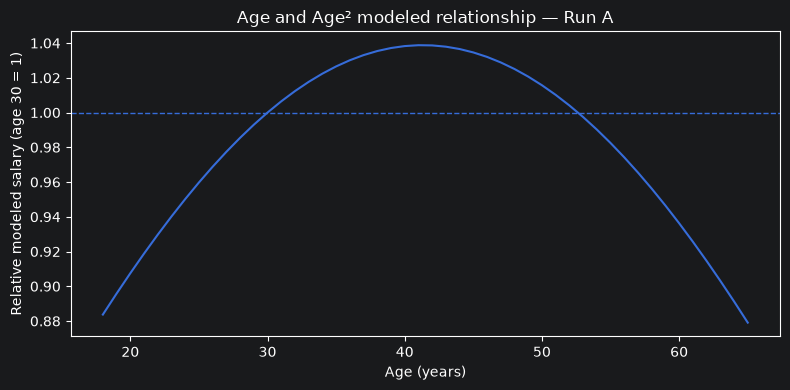


=== RUN A: SELECTED-FEATURE GROUPS ===


,Block,Available columns,Lasso selected,Elastic Net selected
0,Age + Age²,2,2,2
1,YearsCode + YearsCode²,2,2,2
2,YearsCodePro + YearsCodePro²,2,2,2
3,Languages used (multiselect),144,55,57
4,Languages wanted (multiselect),80,57,58


Lasso total: 346 / 522; Elastic Net total: 353 / 522
Common selected columns: 346
Feature groups alone do not establish correlated-feature grouping without further evidence.


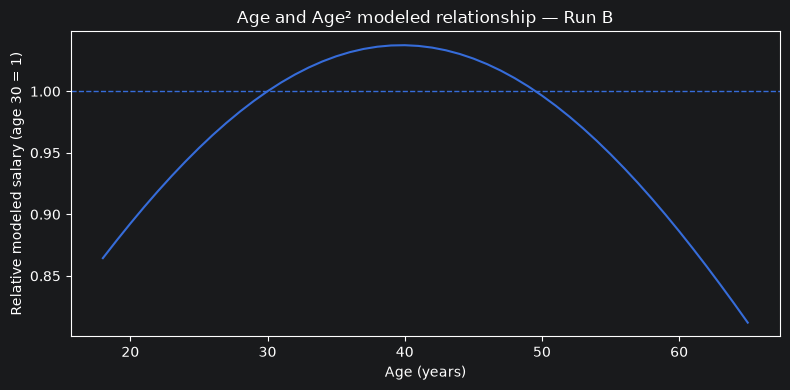


=== RUN B: SELECTED-FEATURE GROUPS ===


,Block,Available columns,Lasso selected,Elastic Net selected
0,Age + Age²,2,2,2
1,YearsCode + YearsCode²,2,2,2
2,YearsCodePro + YearsCodePro²,2,2,2
3,Languages used (multiselect),133,89,89
4,Languages wanted (multiselect),83,68,68


Lasso total: 439 / 541; Elastic Net total: 439 / 541
Common selected columns: 439
Feature groups alone do not establish correlated-feature grouping without further evidence.

Phase 9 interpretation complete; model fitting and test scores are unchanged.


In [14]:
# ============================================================
# PHASE 9e — AGE CURVE + LASSO / ELASTIC NET SELECTION
# ============================================================

for RUN, d in phase9_data.items():
    coeffs = coefficient_tables[RUN]

    if {"num__Age", "num__Age_sq"}.issubset(coeffs.index):
        ages = np.arange(18, 66)
        log_relative = (coeffs["num__Age"] * (ages - 30)
                        + coeffs["num__Age_sq"] * (ages**2 - 30**2))
        plt.figure(figsize=(8, 4))
        plt.plot(ages, np.exp(log_relative))
        plt.axhline(1, linestyle="--", linewidth=1)
        plt.xlabel("Age (years)")
        plt.ylabel("Relative modeled salary (age 30 = 1)")
        plt.title(f"Age and Age² modeled relationship — Run {RUN}")
        plt.tight_layout()
        plt.savefig(RESULTS_DIR / f"age_curve_{RUN}.png", dpi=160)
        plt.show()

    names = np.asarray(d["prep_all"].get_feature_names_out(), dtype=str)
    lasso_keep = np.asarray(d["best"]["lasso"][1].coef_) != 0
    enet_keep = np.asarray(d["best"]["enet_rescaled"][2][0]) != 0

    blocks = {
        "Age + Age²": ["num__Age", "num__Age_sq"],
        "YearsCode + YearsCode²": ["num__YearsCode", "num__YearsCode_sq"],
        "YearsCodePro + YearsCodePro²": ["num__YearsCodePro", "num__YearsCodePro_sq"],
        "Languages used (multiselect)": [name for name in names if name.startswith("remainder__LanguageHaveWorkedWith_")],
        "Languages wanted (multiselect)": [name for name in names if name.startswith("remainder__LanguageWantToWorkWith_")],
    }
    counts = []
    for label, group_names in blocks.items():
        indices = np.flatnonzero(np.isin(names, group_names))
        counts.append({
            "Block": label,
            "Available columns": len(indices),
            "Lasso selected": int(lasso_keep[indices].sum()),
            "Elastic Net selected": int(enet_keep[indices].sum()),
        })

    print(f"\n=== RUN {RUN}: SELECTED-FEATURE GROUPS ===")
    display(pd.DataFrame(counts))
    print(f"Lasso total: {int(lasso_keep.sum())} / {len(names)}; "
          f"Elastic Net total: {int(enet_keep.sum())} / {len(names)}")
    print("Common selected columns:", int((lasso_keep & enet_keep).sum()))
    print("Feature groups alone do not establish correlated-feature grouping without further evidence.")

print("\nPhase 9 interpretation complete; model fitting and test scores are unchanged.")

Both plots show a nonlinear, inverted-U association between age and modeled annual salary, with all other predictors held constant. The curve is normalized to 1.0 at age 30. The modeled maximum is around age 41 in A and age 40 in B, followed by declining relative predictions at older ages. This illustrates the joint Age/`Age_sq` specification; it does not show how a particular person's salary changes over time. Interpret the extremes cautiously.

Run A: Lasso retains 346/522 (66.3%) features; rescaled Elastic Net retains 353/522 (67.6%). All 346 Lasso-selected features are also selected by Elastic Net, which keeps seven additional columns. Among the displayed language indicators, Elastic Net retains 57 versus 55 “languages used” columns and 58 versus 57 “languages wanted” columns. Both methods retain the linear and squared terms for age, coding experience, and professional coding experience.

Run B: Both models select the exact same 439/541 (81.1%) features, including 89 “languages used” and 68 “languages wanted” indicators. Both retain all three displayed linear/quadratic pairs.

These counts show similar, sometimes nested, selected sets, but do not demonstrate the Zou–Hastie correlated-feature grouping effect. Establishing that claim would require examining correlations among candidate features and comparing which correlated alternatives each method retains. At the selected l1_ratio values (0.95 in A; 0.99 in B), Elastic Net is also very Lasso-like.